# Exercise 3. Processes with Memory

### Table of contents
* [Imports](#imports)
* [Data Loading](#data-loading)


### Instructions
- Paper titles are high order random walks happening on a network.
- Reconstruct the single order network based on the random walks in the data.txt file.
   - The nodes in this network are the words.
   - Two words w1 and w2 are connected by a directed w1 -> w2 edge if w2 follows w1 in any title.
   - The edge's weight is the probability that the next word from w1 is w2.
- Reconstruct the high order network of order two based on the random walks. This means you should build the network based on trigrams.
   - Each node is now a pair of oriented words. So node "w1,w2" means that w2 follows w1.
   - Each edge connects pairs of pairs of nodes. For instance, trigram "w1 w2 w3" connects node "w1,w2" to "w2,w3".
   - The edge's weight is still proportional to the probability of transition, but now it is, using the previous example, the probability of ending in w3 via w2 given that we arrived in w2 from w1.
- Print out some examples of random walks on both structures.
   - For the single order network, start from node "^" and end in node "$".
   - For the 2-order network, start from a random node containing "^" and stop when the node contains "$".
   - Compare the random walks you obtain from the two structures and reflect on their differences.
   - NOTE: since you embedded the high order into the structure, the random walk function can be written to work on both network structures (although you don't have to do it).



### Imports <a class="anchor" id="imports"></a>

In [12]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import re

from collections import Counter, defaultdict


### Data Loading <a class="anchor" id="data-loading"></a>

In [47]:
# Read each data as a sequence of words
walks = []

## I will not remove this nodes as they serve as start and end nodes for the network
replacements = {"^": "", "$": ""}
with open("data.txt", "r") as file:
    for line in file:
        if line.strip():
            #clean = re.sub(r'[^\w\s]', '', line)
            # for old, new in replacements.items():
            #     line = line.replace(old, new)
            walks.append(line.split())

print(f"Number of walks: {len(walks)}")
walks[:1] 

Number of walks: 5000


[['^', 'latent', 'dirichlet', 'allocation', '$']]

In [46]:
## Create a counter with the transition between words
transition_counts = Counter()
## Create a vocab
vocab_count = Counter()

for walk in walks:
    for source, target in zip(walk, walk[1:]):
        transition_counts[(source, target)] += 1
        vocab_count[source] += 1

vocab_count['$'] = 5000


print(transition_counts.items())
print('len vocab:', len(vocab_count))
print(vocab_count.items())

dict_items([(('^', 'latent'), 2), (('latent', 'dirichlet'), 2), (('dirichlet', 'allocation'), 2), (('allocation', '$'), 3), (('^', 'statistical'), 13), (('statistical', 'comparisons'), 1), (('comparisons', 'of'), 3), (('of', 'classifiers'), 5), (('classifiers', 'over'), 2), (('over', 'multiple'), 2), (('multiple', 'data'), 2), (('data', 'sets'), 8), (('sets', '$'), 60), (('^', 'scikit-learn:'), 1), (('scikit-learn:', 'machine'), 1), (('machine', 'learning'), 32), (('learning', 'in'), 45), (('in', 'python'), 4), (('python', '$'), 5), (('^', 'sparse'), 17), (('sparse', 'bayesian'), 3), (('bayesian', 'learning'), 10), (('learning', 'and'), 24), (('and', 'the'), 31), (('the', 'relevance'), 2), (('relevance', 'vector'), 3), (('vector', 'machine'), 19), (('machine', '$'), 16), (('^', 'liblinear:'), 1), (('liblinear:', 'a'), 1), (('a', 'library'), 5), (('library', 'for'), 11), (('for', 'large'), 9), (('large', 'linear'), 1), (('linear', 'classification'), 5), (('classification', '$'), 63), ((

In [48]:
## Create a directed graph 
G_manual = nx.DiGraph() 

for (s,t), tuple_count in transition_counts.items():
    ## prob of going from source (s) to target (t)
    source_count = vocab_count[s]
    weight = 0 
    if source_count > 0:
        weight = tuple_count / source_count
    G_manual.add_edge(s, t, weight = weight)
    

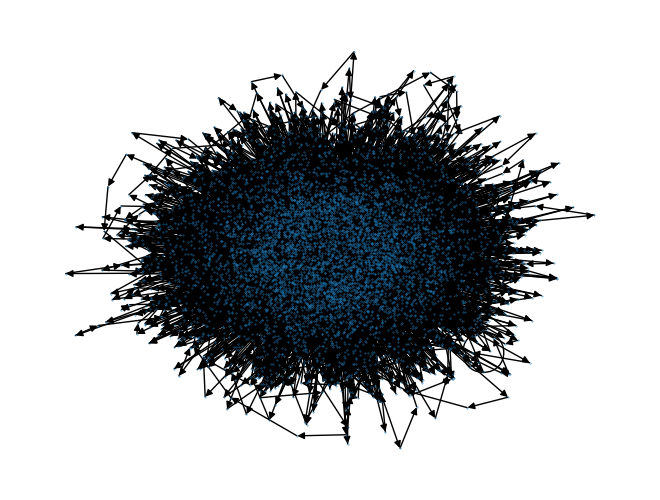

In [50]:
nx.draw(G_manual, node_size=0.1)